# 4 · Passer en 3D : l'élément hexaédrique

*Notebook 4 du cours. Il suppose le [notebook 1](01_discretisation.ipynb) (grille, nœuds, numérotation), le [notebook 2](02_fem_1d.ipynb) (assemblage, $\mathbf K\mathbf u=\mathbf f$) et surtout le [notebook 3](03_elasticite_2d.ipynb) (élément Q1 2D, matrice $\mathbf B$, $\mathbf K_e^0$).*

Le notebook 3 a construit la matrice de rigidité d'un élément à 4 nœuds. Un bras de drone est un objet 3D : il faut un élément à **8 nœuds**, l'**hexaèdre** (une brique). La bonne nouvelle : **c'est la même construction, avec les mêmes formules**. La numérotation des coins par code binaire (notebook 1) permet d'écrire *un seul* code valable en 2D et en 3D. Ce notebook :

- montre que rien de nouveau n'est nécessaire, à part des tableaux plus grands ;
- **valide** la matrice $24\times24$ obtenue, par cinq vérifications indépendantes (dont un lien exact avec le 2D du notebook 3) ;
- l'assemble sur une grille 3D et compare une **poutre console 3D** à la théorie des poutres ;
- mesure ce que la 3D coûte vraiment (mémoire, remplissage, temps, conditionnement), ce qui motive les leçons 5 et 6.

**C'est le premier notebook qui s'appuie sur du code du projet** : l'élément vit désormais dans `src/aeroptimizer/fem/elements.py` (et la loi de comportement 3D dans `materials.py`, la connectivité dans `grid.py`), avec ses tests dans `tests/unit/`. Le notebook montre ce code, l'exécute et le valide ; il ne le recopie pas.

**Plan.**
1. Ce qui change du 2D au 3D ; 2. Les huit coins et les fonctions de forme ; 3. Quadrature de Gauss $2\times2\times2$ ;
4. La matrice $\mathbf B$ ($6\times24$) et $\mathbf K_e^0$ ; 5. Cinq vérifications ;
6. Assemblage 3D ; 7. Console 3D contre la théorie des poutres ; 8. Le coût de la 3D.

In [1]:
import sys, time, inspect
from pathlib import Path

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# le dossier du projet (celui qui contient src/) est cherché en remontant depuis le notebook
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))      # le package du projet
sys.path.insert(0, str(RACINE / "tests"))    # les oracles indépendants (tests/reference)

from aeroptimizer.fem import elements as el
from aeroptimizer.grid import Grid, Connectivity
from aeroptimizer.materials import Orthotropic

torch.set_default_dtype(torch.float64)       # convention du projet : calcul en float64 (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=130)

## 1. Ce qui change du 2D au 3D

Chaque brique de la construction 2D a un équivalent 3D. Rien n'est conceptuellement nouveau :

| Ingrédient | 2D (notebook 3) | 3D (ce notebook) |
|---|---|---|
| axes | $(x,z)$ | $(x,y,z)$, $z$ = sens d'impression |
| déplacement par nœud | $(u_x,u_z)$ : 2 | $(u_x,u_y,u_z)$ : 3 |
| nœuds par élément | 4 (carré) | 8 (brique) |
| inconnues par élément | 8 | 24 |
| déformation (Voigt) | $(\varepsilon_{xx},\varepsilon_{zz},\gamma_{xz})$ : 3 | $(\varepsilon_{xx},\varepsilon_{yy},\varepsilon_{zz},\gamma_{yz},\gamma_{xz},\gamma_{xy})$ : 6 |
| loi de Hooke $\mathbf C$ | $3\times3$ (contraintes ou déformations planes) | $6\times6$ : **directement** $\mathbf S^{-1}$, plus de « plan » à choisir |
| matrice $\mathbf B$ | $3\times8$ | $6\times24$ |
| points de Gauss | $2\times2=4$ | $2\times2\times2=8$ |
| mouvements rigides (noyau de $\mathbf K_e^0$) | 3 (2 translations, 1 rotation) | **6** (3 translations, 3 rotations) |

Les chiffres ci-dessus sont tous calculés par le code du projet :

In [2]:
mat = Orthotropic.isotropic(1.0, 0.3)
print(f"{'':28s}{'2D':>8s}{'3D':>8s}")
for nom, f in [
    ("nœuds par élément",          lambda d: 2 ** d),
    ("inconnues par élément",      lambda d: d * 2 ** d),
    ("lignes de Voigt",            lambda d: mat.stiffness(d).shape[0]),
    ("points de Gauss",            lambda d: el.gauss_points(d)[0].shape[0]),
    ("coefficients de K_e^0",      lambda d: (d * 2 ** d) ** 2),
]:
    print(f"{nom:28s}{f(2):8d}{f(3):8d}")

                                  2D      3D
nœuds par élément                  4       8
inconnues par élément              8      24
lignes de Voigt                    3       6
points de Gauss                    4       8
coefficients de K_e^0             64     576


## 2. Les huit coins et les fonctions de forme

Au notebook 1, les coins du carré étaient numérotés par un **code binaire** : le coin $a$ s'écrit en binaire $(b_0,b_1)$, le premier bit $b_0$ (poids fort) repère la position sur $x$, le dernier la position sur $z$. En 3D on ajoute simplement un bit : $(b_0,b_1,b_2)$ pour $(x,y,z)$. Un bit à 0 signifie le côté $-1$ de l'axe, un bit à 1 le côté $+1$ : le coin 5 s'écrit $101$, c'est le coin $(+1,-1,+1)$.

Sur l'élément de référence $[-1,1]^d$, on note $s_{a,k}=2b_k-1\in\{-1,+1\}$ la coordonnée du coin $a$ sur l'axe $k$, et la fonction de forme est le **produit** de facteurs 1D :

$$
N_a(\boldsymbol\xi)=\prod_{k=0}^{d-1}\frac{1+s_{a,k}\,\xi_k}{2}.
$$

C'est *exactement* la formule du notebook 1, écrite pour $d$ quelconque : le même code sert en 2D et 3D.

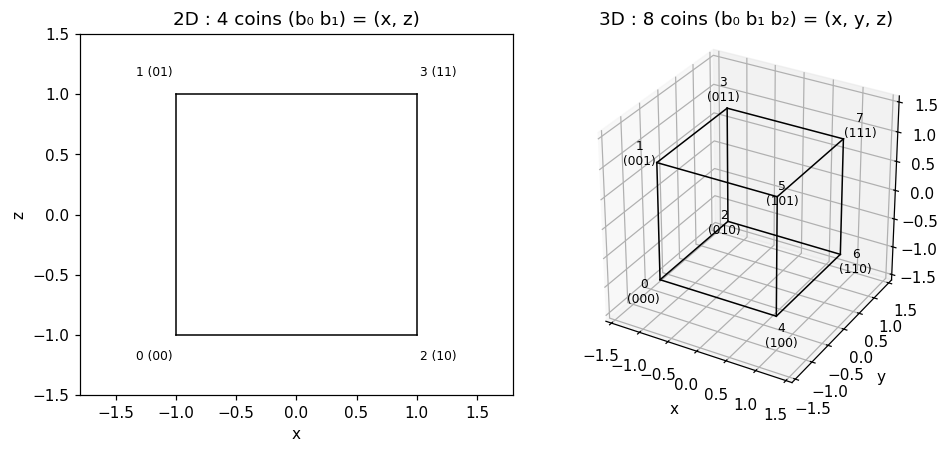

signes s_{a,k} des 8 coins (colonnes x, y, z) :
[[-1 -1 -1 -1  1  1  1  1]
 [-1 -1  1  1 -1 -1  1  1]
 [-1  1 -1  1 -1  1 -1  1]]


In [3]:
def dessiner_element(ax, d):
    # Un élément de référence avec ses coins numérotés : numéro (bits).
    s = el.local_node_signs(d).numpy()
    for a in range(2 ** d):
        for b in range(a + 1, 2 ** d):
            if (s[a] != s[b]).sum() == 1:                     # deux coins voisins diffèrent d'un seul bit
                ax.plot(*zip(s[a] if d == 3 else s[a][[0, 1]], s[b] if d == 3 else s[b][[0, 1]]), "k-", lw=1)
    for a in range(2 ** d):
        bits = "".join(str(int(v)) for v in (s[a] + 1) / 2)
        pos = s[a] * 1.18
        if d == 3:
            ax.text(*pos, f"{a}\n({bits})", ha="center", va="center", fontsize=8)
        else:
            ax.text(*pos, f"{a} ({bits})", ha="center", va="center", fontsize=8)
    ax.set_xlabel("x")

fig = plt.figure(figsize=(9, 4))
ax2 = fig.add_subplot(1, 2, 1)
dessiner_element(ax2, 2); ax2.set_ylabel("z"); ax2.set_xlim(-1.8, 1.8); ax2.set_ylim(-1.5, 1.5)
ax2.set_aspect("equal"); ax2.set_title("2D : 4 coins (b₀ b₁) = (x, z)")
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
dessiner_element(ax3, 3); ax3.set_ylabel("y"); ax3.set_zlabel("z")
ax3.set_title("3D : 8 coins (b₀ b₁ b₂) = (x, y, z)"); ax3.set_box_aspect((1, 1, 1))
ax3.set_xlim(-1.6, 1.6); ax3.set_ylim(-1.6, 1.6); ax3.set_zlim(-1.6, 1.6)
plt.tight_layout(); plt.show()

print("signes s_{a,k} des 8 coins (colonnes x, y, z) :")
print(el.local_node_signs(3).numpy().astype(int).T)

Vérifions que la formule fait ce qu'on attend d'une fonction de forme : $N_a$ vaut 1 sur son coin et 0 sur les sept autres (c'est ce qui rend le déplacement interpolé *égal* aux valeurs nodales), et les $N_a$ somment à 1 partout (un déplacement constant est reproduit exactement).

In [4]:
def N(xi, d):
    # les 2^d fonctions de forme au point xi (formule du texte), tableau de taille 2^d
    s = el.local_node_signs(d).numpy()
    return np.prod((1 + s * np.asarray(xi)) / 2, axis=1)

for d in (2, 3):
    s = el.local_node_signs(d).numpy()
    aux_coins = np.array([N(s[b], d) for b in range(2 ** d)])          # N_a au coin b
    print(f"d = {d} : N_a(coin b) = delta_ab :", np.allclose(aux_coins, np.eye(2 ** d)))
    rng = np.random.default_rng(0)
    pts = rng.uniform(-1, 1, size=(1000, d))
    print(f"      somme des N_a = 1 en 1000 points au hasard :", np.allclose([N(p, d).sum() for p in pts], 1.0))
    # le code du projet évalue les N_a aux points de Gauss : même formule, même résultat
    xi, _ = el.gauss_points(d)
    print(f"      el.shape_values = formule du texte aux points de Gauss :",
          np.allclose(el.shape_values(d).numpy(), [N(p, d) for p in xi.numpy()]))

d = 2 : N_a(coin b) = delta_ab : True
      somme des N_a = 1 en 1000 points au hasard : True
      el.shape_values = formule du texte aux points de Gauss : True
d = 3 : N_a(coin b) = delta_ab : True
      somme des N_a = 1 en 1000 points au hasard : True
      el.shape_values = formule du texte aux points de Gauss : True


## 3. Quadrature de Gauss $2\times2\times2$

La matrice $\mathbf K_e^0$ est une **intégrale** sur l'élément. On ne la calcule pas symboliquement : on l'approche par une somme pondérée en quelques points, la **quadrature de Gauss**. En 1D, deux points $\pm1/\sqrt3$ (poids 1) intègrent exactement tout polynôme de degré $\le3$ sur $[-1,1]$. En $d$ dimensions on prend le **produit** : $2^d$ points, tous de poids 1, aux coins du cube $[-1/\sqrt3,1/\sqrt3]^d$ — c'est-à-dire les signes $s_{a,k}$ divisés par $\sqrt3$, dans le même ordre que les coins.

Cela suffit : $\partial N_a/\partial x_k$ ne dépend pas de $\xi_k$ et est de degré 1 en chacune des autres variables ; le produit $\mathbf B^\top\mathbf C\mathbf B$ est donc de degré $\le2$ par variable, dans la zone où Gauss est exact (le jacobien est constant sur une grille régulière). **L'intégration est donc exacte, pas approchée.**

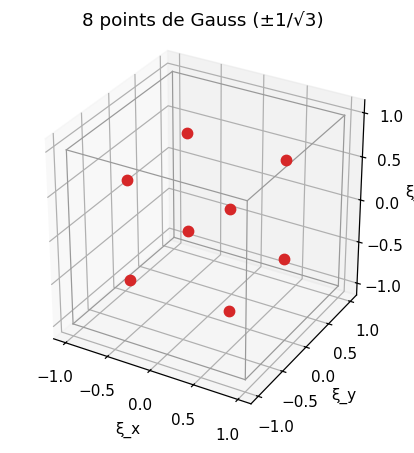

monôme ξ^p η^q ζ^r      intégrale exacte    somme de Gauss
   ξ^0 η^0 ζ^0             8.000000          8.000000   exact
   ξ^2 η^0 ζ^0             2.666667          2.666667   exact
   ξ^2 η^2 ζ^2             0.296296          0.296296   exact
   ξ^3 η^3 ζ^3             0.000000          0.000000   exact
   ξ^1 η^2 ζ^3             0.000000          0.000000   exact
   ξ^4 η^0 ζ^0             1.600000          0.888889   FAUX (degré 4 > 3)


In [5]:
pts, w = el.gauss_points(3)
fig = plt.figure(figsize=(4.2, 4))
ax = fig.add_subplot(111, projection="3d")
s = el.local_node_signs(3).numpy()
for a in range(8):
    for b in range(a + 1, 8):
        if (s[a] != s[b]).sum() == 1:
            ax.plot(*zip(s[a], s[b]), color="0.6", lw=0.8)
ax.scatter(*pts.numpy().T, s=45, color="C3", depthshade=False)
ax.set_xlabel("ξ_x"); ax.set_ylabel("ξ_y"); ax.set_zlabel("ξ_z"); ax.set_box_aspect((1, 1, 1))
ax.set_title("8 points de Gauss (±1/√3)")
plt.tight_layout(); plt.show()

print("monôme ξ^p η^q ζ^r      intégrale exacte    somme de Gauss")
for p, q, r in [(0, 0, 0), (2, 0, 0), (2, 2, 2), (3, 3, 3), (1, 2, 3), (4, 0, 0)]:
    exact = np.prod([0.0 if k % 2 else 2.0 / (k + 1) for k in (p, q, r)])
    gauss = float((w.numpy() * np.prod(pts.numpy() ** np.array([p, q, r]), axis=1)).sum())
    print(f"   ξ^{p} η^{q} ζ^{r}   {exact:18.6f}  {gauss:16.6f}   {'exact' if abs(exact - gauss) < 1e-14 else 'FAUX (degré 4 > 3)'}")

Le dernier monôme, de degré 4 en $\xi$, n'est pas intégré exactement : c'est la limite de la règle, qui n'est jamais atteinte ici.

## 4. La matrice $\mathbf B$ ($6\times24$) et la matrice $\mathbf K_e^0$

La matrice $\mathbf B$ relie les 24 déplacements nodaux au vecteur de 6 déformations au point de Gauss : $\boldsymbol\varepsilon=\mathbf B\mathbf u_e$. Chaque nœud $a$ contribue 3 colonnes ($u_x,u_y,u_z$) ; chaque ligne correspond à une composante de Voigt :

| ligne | déformation | colonnes non nulles du nœud $a$ |
|---|---|---|
| 0 | $\varepsilon_{xx}=\partial_xu_x$ | $u_x$ : $\partial_xN_a$ |
| 1 | $\varepsilon_{yy}=\partial_yu_y$ | $u_y$ : $\partial_yN_a$ |
| 2 | $\varepsilon_{zz}=\partial_zu_z$ | $u_z$ : $\partial_zN_a$ |
| 3 | $\gamma_{yz}=\partial_zu_y+\partial_yu_z$ | $u_y$ : $\partial_zN_a$, $u_z$ : $\partial_yN_a$ |
| 4 | $\gamma_{xz}=\partial_zu_x+\partial_xu_z$ | $u_x$ : $\partial_zN_a$, $u_z$ : $\partial_xN_a$ |
| 5 | $\gamma_{xy}=\partial_yu_x+\partial_xu_y$ | $u_x$ : $\partial_yN_a$, $u_y$ : $\partial_xN_a$ |

Les trois premières lignes sont les allongements, les trois dernières les cisaillements d'ingénierie, dans l'ordre de Voigt du projet. Voici le code du projet qui construit $\mathbf B$ aux 8 points de Gauss *d'un seul coup* (sans boucle sur les points ni sur les nœuds : seulement sur les composantes), puis $\mathbf K_e^0=t\sum_g w_g\det\mathbf J\,\mathbf B_g^\top\mathbf C_0\mathbf B_g$ :

In [6]:
print(inspect.getsource(el.strain_displacement))
print(inspect.getsource(el.elasticity_ke0))

def strain_displacement(grads: torch.Tensor) -> torch.Tensor:
    """B matrices from shape gradients (G, 2**d, d): (G, n_voigt, d*2**d), dof = d*a + c.

    Rows: d normal strains eps_kk = d u_k / d x_k, then the engineering shears
    gamma_ij = du_i/dx_j + du_j/dx_i in the Voigt order of C-CONV-06.
    """
    G, n_nodes, d = grads.shape
    pairs = _SHEAR_PAIRS[d]
    B = torch.zeros(G, d + len(pairs), d * n_nodes, dtype=grads.dtype)
    cols = d * torch.arange(n_nodes)
    for k in range(d):
        B[:, k, cols + k] = grads[:, :, k]
    for r, (i, j) in enumerate(pairs, start=d):
        B[:, r, cols + i] = grads[:, :, j]
        B[:, r, cols + j] = grads[:, :, i]
    return B

def elasticity_ke0(
    d: int, h: tuple[float, ...], C0: torch.Tensor, thickness: float = 1.0
) -> torch.Tensor:
    """Mechanical element matrix, shape (d*2**d, d*2**d). Symmetric PSD, rank deficit 3 (2D) / 6 (3D).

    Ke0 = t * sum_g w_g detJ B_g^T C0 B_g   (thickness t only for 2D plane stress/strain).

Le gradient en $x$ s'obtient depuis le gradient en $\xi$ par $\nabla_{\mathbf x}N_a=\mathbf J^{-1}\nabla_{\boldsymbol\xi}N_a$, avec $\mathbf J=\mathrm{diag}(h_k/2)$ constant (grille régulière) : c'est ce qui permet de n'avoir qu'**une seule** matrice $\mathbf K_e^0$ pour tous les éléments. Voici $\mathbf B$ au premier point de Gauss d'un cube unité, et la matrice $\mathbf K_e^0$ ($E=1$, $\nu=0{,}3$, cube de côté 1) :

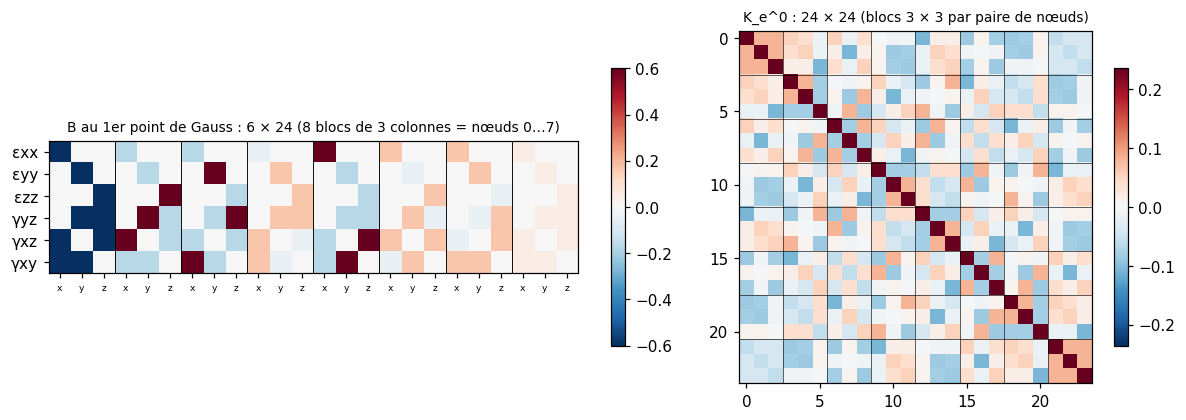

K_e^0 est de taille (24, 24) ; bloc diagonal du nœud 0 :
[[0.235  0.0801 0.0801]
 [0.0801 0.235  0.0801]
 [0.0801 0.0801 0.235 ]]


In [7]:
h = (1.0, 1.0, 1.0)
C0 = Orthotropic.isotropic(1.0, 0.3).stiffness(3)
B = el.strain_displacement(el.shape_grads(3, h))          # (8 points de Gauss, 6, 24)
K = el.elasticity_ke0(3, h, C0).numpy()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
im = axs[0].imshow(B[0].numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="equal")
axs[0].set_yticks(range(6), ["εxx", "εyy", "εzz", "γyz", "γxz", "γxy"])
axs[0].set_xticks(range(24), ["x", "y", "z"] * 8, fontsize=6)
for a in range(1, 8): axs[0].axvline(3 * a - 0.5, color="k", lw=0.6)
axs[0].set_title("B au 1er point de Gauss : 6 × 24 (8 blocs de 3 colonnes = nœuds 0…7)", fontsize=9)
fig.colorbar(im, ax=axs[0], shrink=0.7)
im = axs[1].imshow(K, cmap="RdBu_r", vmin=-np.abs(K).max(), vmax=np.abs(K).max())
for a in range(1, 8):
    axs[1].axvline(3 * a - 0.5, color="k", lw=0.4); axs[1].axhline(3 * a - 0.5, color="k", lw=0.4)
axs[1].set_title("K_e^0 : 24 × 24 (blocs 3 × 3 par paire de nœuds)", fontsize=9)
fig.colorbar(im, ax=axs[1], shrink=0.7)
plt.tight_layout(); plt.show()
print("K_e^0 est de taille", K.shape, "; bloc diagonal du nœud 0 :")
print(K[:3, :3])

## 5. Cinq vérifications

Une matrice $24\times24$ ne se relit pas à l'œil. Comme au notebook 3, on la valide par des propriétés qu'elle **doit** avoir, vérifiées avec des matériaux et des tailles d'élément *non triviaux* (isotrope transverse comme les pièces imprimées, $h$ différent selon chaque axe, pour ne pas laisser passer une confusion entre axes).

**Vérification 1 — symétrie et énergie positive.** $\mathbf K_e^0$ doit être symétrique (énergie bien définie) et ses valeurs propres $\ge0$ (aucun déplacement ne fournit d'énergie).

**Vérification 2 — six modes rigides.** Une brique qui se translate ou tourne en bloc ne se déforme pas : $\mathbf K_e^0\mathbf u=\mathbf 0$. Il y a **6** tels mouvements (3 translations, 3 rotations) donc exactement 6 valeurs propres nulles et 18 strictement positives.

1) asymétrie relative : 1.3214278883088352e-16
   plus petite valeur propre : -2.07e-16 (>= -1e-12 * ||K||) True

2) valeurs propres (8 plus petites) : [-0.     -0.      0.      0.      0.      0.      0.0069  0.0951]
   nombre de valeurs propres nulles : 6 (attendu : 6)
   translation x        ||K u|| / (||K|| ||u||) = 4.3e-17
   translation y        ||K u|| / (||K|| ||u||) = 2.0e-17
   translation z        ||K u|| / (||K|| ||u||) = 1.3e-17
   rotation autour de x ||K u|| / (||K|| ||u||) = 1.8e-17
   rotation autour de y ||K u|| / (||K|| ||u||) = 6.4e-17
   rotation autour de z ||K u|| / (||K|| ||u||) = 6.2e-17


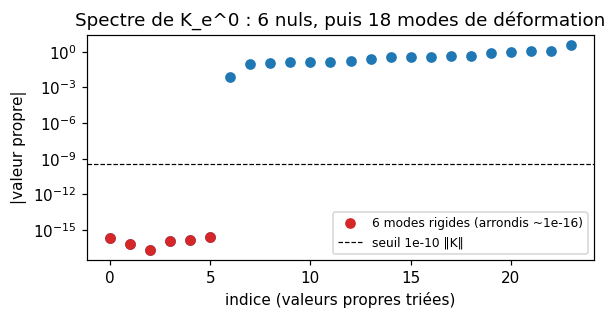

In [8]:
ti = Orthotropic.transversely_isotropic(Ep=1.0, Ez=0.75, nup=0.35, nupz=0.35, Gz=0.29)   # ~ placeholders FDM
h = (0.5, 2.0, 1.25)                                  # éléments non cubiques, pour démasquer toute confusion d'axes
C0 = ti.stiffness(3)
Ke = el.elasticity_ke0(3, h, C0).numpy()

# --- 1. symétrie et positivité
print("1) asymétrie relative :", np.abs(Ke - Ke.T).max() / np.abs(Ke).max())
ev = np.linalg.eigvalsh((Ke + Ke.T) / 2)
print("   plus petite valeur propre :", f"{ev.min():.2e}", "(>= -1e-12 * ||K||)", ev.min() >= -1e-12 * ev.max())

# --- 2. six modes rigides
print("\n2) valeurs propres (8 plus petites) :", ev[:8])
print("   nombre de valeurs propres nulles :", int((np.abs(ev) < 1e-10 * ev.max()).sum()), "(attendu : 6)")

x = (el.local_node_signs(3).numpy() * np.array(h) / 2)          # coordonnées des 8 coins (centrées)
modes = {}
for c, nom in enumerate("xyz"):
    u = np.zeros((8, 3)); u[:, c] = 1; modes[f"translation {nom}"] = u
for (i, j), nom in zip([(1, 2), (0, 2), (0, 1)], ["autour de x", "autour de y", "autour de z"]):
    u = np.zeros((8, 3)); u[:, i], u[:, j] = -x[:, j], x[:, i]; modes[f"rotation {nom}"] = u
for nom, u in modes.items():
    u = u.reshape(-1)
    print(f"   {nom:20s} ||K u|| / (||K|| ||u||) = {np.linalg.norm(Ke @ u) / (np.abs(ev).max() * np.linalg.norm(u)):.1e}")

plt.figure(figsize=(5.6, 3.0))
plt.semilogy(range(24), np.maximum(np.abs(ev), 1e-18), "o", color="C0")
plt.semilogy(range(6), np.maximum(np.abs(ev[:6]), 1e-18), "o", color="C3", label="6 modes rigides (arrondis ~1e-16)")
plt.axhline(1e-10 * ev.max(), color="k", ls="--", lw=0.8, label="seuil 1e-10 ‖K‖")
plt.xlabel("indice (valeurs propres triées)"); plt.ylabel("|valeur propre|"); plt.legend(fontsize=8)
plt.title("Spectre de K_e^0 : 6 nuls, puis 18 modes de déformation"); plt.tight_layout(); plt.show()

**Vérification 3 — le patch test.** On impose aux 8 coins un champ de déplacement **affine** $\mathbf u=\boldsymbol\varepsilon\,\mathbf x$ : la déformation est partout la même, et la contrainte aussi, $\boldsymbol\sigma=\mathbf C_0\boldsymbol\varepsilon$. Une contrainte constante sur une brique est équivalente à des forces aux coins, qu'on sait écrire à la main : le coin $a$ reçoit

$$
\mathbf f_a=\boldsymbol\sigma\int_e\nabla N_a\,dV,\qquad \int_e\partial_kN_a\,dV=\frac{V\,s_{a,k}}{2^{d-1}h_k},
$$

ce qui est la répartition à égalité de la force sur chaque face entre ses coins. L'élément doit donc satisfaire $\mathbf K_e^0\mathbf u=\mathbf f$ avec *ces* forces, calculées sans aucune matrice $\mathbf B$. Si $\mathbf B$ ou $\mathbf C_0$ était faux, le test échouerait (ici avec les six composantes de déformation actives en même temps).

In [9]:
eps_voigt = np.array([0.3, -0.1, 0.2, 0.15, -0.25, 0.05])         # (xx, yy, zz, yz, xz, xy), cisaillements d'ingénieur
def tenseur(v):                                                    # vecteur de Voigt -> tenseur symétrique 3x3
    T = np.diag(v[:3]).astype(float)
    for r, (i, j) in enumerate([(1, 2), (0, 2), (0, 1)]):
        T[i, j] = T[j, i] = v[3 + r]
    return T
eps = tenseur(eps_voigt / np.array([1, 1, 1, 2, 2, 2]))             # tenseur : epsilon_ij = gamma_ij / 2
sigma = tenseur(C0.numpy() @ eps_voigt)                              # contrainte : pas de facteur 2 (C est en Voigt d'ingénieur)

u = (x @ eps).reshape(-1)                                            # champ affine aux coins
V = np.prod(h)
s_ = el.local_node_signs(3).numpy()
f_attendu = ((V * s_ / (2 ** 2 * np.array(h))) @ sigma.T).reshape(-1)   # formule du texte, sans B
print("3) ||K u - f|| / ||f|| =", np.linalg.norm(Ke @ u - f_attendu) / np.linalg.norm(f_attendu))

3) ||K u - f|| / ||f|| = 2.817579951943695e-16


**Vérification 4 — retrouver le 2D du notebook 3.** Une plaque 3D qui ne bouge pas selon $y$ ($u_y=0$ et $u_x,u_z$ identiques sur ses deux faces) est dans un état de **déformations planes** d'épaisseur $h_y$ : son énergie doit être celle de l'élément 2D, avec la loi $\mathbf C^{\text{déf. planes}}$ et $t=h_y$. On relie les deux numérotations (nœud 3D $4b_x+2b_y+b_z$ vers nœud 2D $2b_x+b_z$) par une matrice de sélection $\mathbf T$ ($24\times8$) et on compare $\mathbf T^\top\mathbf K^{3D}_e\mathbf T$ à $\mathbf K_e^{2D}$. C'est un **lien exact** entre les deux notebooks : le 3D contient le 2D.

In [10]:
T = np.zeros((24, 8))
for a3 in range(8):
    bx, bz = (a3 >> 2) & 1, a3 & 1                    # bits x et z du coin 3D (b_y = (a3 >> 1) & 1 est ignoré)
    a2 = 2 * bx + bz                                  # coin 2D correspondant
    T[3 * a3 + 0, 2 * a2 + 0] = 1                     # u_x identique sur les deux faces y
    T[3 * a3 + 2, 2 * a2 + 1] = 1                     # u_z identique ; u_y reste nul

K3 = el.elasticity_ke0(3, h, C0).numpy()
K2 = el.elasticity_ke0(2, (h[0], h[2]), ti.stiffness(2, "strain"), thickness=h[1]).numpy()
print("4) max |T^T K3D T - K2D(déf. planes, t = h_y)| / max |K2D| =", np.abs(T.T @ K3 @ T - K2).max() / np.abs(K2).max())
print("   (et avec la loi de contraintes planes, ce n'est PAS égal :",
      np.abs(T.T @ K3 @ T - el.elasticity_ke0(2, (h[0], h[2]), ti.stiffness(2, "stress"), thickness=h[1]).numpy()).max() / np.abs(K2).max(), ")")

4) max |T^T K3D T - K2D(déf. planes, t = h_y)| / max |K2D| = 3.578583426941313e-16
   (et avec la loi de contraintes planes, ce n'est PAS égal : 0.22938250777498695 )


**Vérification 5 — un oracle indépendant.** Les vérifications précédentes testent des *propriétés*. On finit en comparant à une seconde implémentation écrite autrement : `tests/reference/assembly_numpy.py::ke0_by_loops`, en NumPy avec des boucles explicites sur les points de Gauss, les nœuds, et des lignes de $\mathbf B$ écrites une à une à la main (aucun code partagé avec le package). On prend un matériau **orthotrope complet** (9 constantes distinctes) pour exercer tous les termes.

In [11]:
from reference.assembly_numpy import ke0_by_loops

ortho = Orthotropic(E1=1.0, E2=0.8, E3=0.6, G23=0.2, G13=0.25, G12=0.3, nu12=0.3, nu13=0.25, nu23=0.2)
for d, hh in ((2, h[::2]), (3, h)):
    C = ortho.stiffness(d, "stress")
    K_pkg = el.elasticity_ke0(d, hh, C).numpy()
    K_ref = ke0_by_loops(d, hh, C.numpy())
    print(f"5) d = {d} : max |K_package - K_boucles| / max |K| = {np.abs(K_pkg - K_ref).max() / np.abs(K_ref).max():.1e}")

5) d = 2 : max |K_package - K_boucles| / max |K| = 1.2e-16
5) d = 3 : max |K_package - K_boucles| / max |K| = 3.3e-16


Ces propriétés sont aussi des **tests automatiques** (`tests/unit/test_element.py`, `test_material.py`, `test_grid.py`) : on les relance par `pytest` à chaque modification du code. Elles ont été vérifiées sensibles : une erreur volontaire sur l'ordre des cisaillements, sur un facteur $1/2$ ou sur le jacobien fait échouer au moins un test.

## 6. Assemblage 3D

L'assemblage du notebook 3 était écrit pour une grille 2D. Grâce au code binaire, la table de connectivité (`Connectivity`, dans `grid.py`) est la même en $d$ dimensions, **sans boucle sur les éléments** : le nœud de coin $a$ de l'élément $(i_0,\dots,i_{d-1})$ est
$$
n=\sum_k (i_k+b_k(a))\,\text{pas}_k,\qquad \text{pas}_k=\prod_{m>k}(n_m+1)\ \ (\text{ordre C}),
$$
et ses ddl sont $d\,n+c$ pour $c=0,\dots,d-1$. On le vérifie sur une grille $2\times2\times2$ éléments (nœuds $3\times3\times3$) :

In [12]:
g = Grid((2, 2, 2), (1.0, 1.0, 1.0))
edof = Connectivity(g, ncomp=3).edof                       # (8 éléments, 24 ddl)
print("forme de edof :", tuple(edof.shape))
print("nœuds de l'élément 0 :", (edof[0, ::3] // 3).tolist(), " (pas selon x, y, z : 9, 3, 1)")
print("nœuds de l'élément 7 :", (edof[7, ::3] // 3).tolist())
print("ddl de l'élément 0, nœud par nœud :\n", edof[0].reshape(8, 3).numpy().T)

forme de edof : (8, 24)
nœuds de l'élément 0 : [0, 1, 3, 4, 9, 10, 12, 13]  (pas selon x, y, z : 9, 3, 1)
nœuds de l'élément 7 : [13, 14, 16, 17, 22, 23, 25, 26]
ddl de l'élément 0, nœud par nœud :
 [[ 0  3  9 12 27 30 36 39]
 [ 1  4 10 13 28 31 37 40]
 [ 2  5 11 14 29 32 38 41]]


Le nœud 0 est en $(0,0,0)$ ; ses voisins sont le nœud 1 (un pas en $z$), 3 (un pas en $y$), 9 (un pas en $x$) : l'ordre C, dernier axe le plus rapide, comme au notebook 1. L'assemblage lui-même est le même gather/scatter qu'avant (notebook 3) ; seule la taille de $\mathbf K_e^0$ change, et la fonction est écrite **une fois** pour 2D et 3D :

In [13]:
def assembler(grille, Ke0, ncomp, s_e=None):
    # K = sum_e s_e A_e^T Ke0 A_e, creuse (COO -> CSR). Valable en 2D comme en 3D.
    ed = Connectivity(grille, ncomp).edof.numpy()                      # (Ne, m)
    Ne, m = ed.shape
    N = grille.n_dofs(ncomp)
    lignes = np.broadcast_to(ed[:, :, None], (Ne, m, m))
    colonnes = np.broadcast_to(ed[:, None, :], (Ne, m, m))
    s_e = np.ones(Ne) if s_e is None else s_e
    valeurs = s_e[:, None, None] * Ke0.numpy()[None, :, :]
    return sp.coo_matrix((valeurs.ravel(), (lignes.ravel(), colonnes.ravel())), shape=(N, N)).tocsr()

# test : sans appui, K a exactement 6 modes rigides en 3D (comme l'élément isolé)
gp = Grid((3, 2, 2), (1.0, 1.0, 1.0))
Kp = assembler(gp, el.elasticity_ke0(3, gp.h, Orthotropic.isotropic(1.0, 0.3).stiffness(3)), 3)
vp = np.linalg.eigvalsh(Kp.toarray())
print(f"K : {Kp.shape[0]} x {Kp.shape[0]} ; valeurs propres nulles sans appui : {int((np.abs(vp) < 1e-10 * vp.max()).sum())} (attendu : 6)")

K : 108 x 108 ; valeurs propres nulles sans appui : 6 (attendu : 6)


## 7. Console 3D contre la théorie des poutres

Même épreuve qu'au notebook 3, mais en 3D : une poutre de section carrée $W\times H=10\times10$ mm et de longueur $L=100$ mm, **encastrée** sur la face $x=0$ (les trois déplacements bloqués sur toute la face), chargée à l'autre bout par une force verticale $F=10$ N répartie sur la face (trapèzes en $y$ et $z$). Matériau : $E=2$ GPa, $\nu=0{,}3$ (type PLA, notebook 3).

La référence est la théorie de Timoshenko, comme en 2D : $\delta=\dfrac{FL^3}{3EI}+\dfrac{FL}{\kappa GA}$, avec $I=WH^3/12$, $A=WH$ et le coefficient de cisaillement de Cowper pour une section rectangulaire, $\kappa=\dfrac{10(1+\nu)}{12+11\nu}\approx0{,}85$ (valeur classique de la littérature ; le terme de cisaillement ne pèse ici que moins de 1 % de la flèche, donc le choix exact de $\kappa$ est secondaire). On raffine le maillage : $n$ éléments dans la hauteur et la largeur, $10n$ dans la longueur.

In [14]:
def console_3d(mat, L, W, H, n, F, rapport=10):
    nx, ny, nz = rapport * n, max(1, round(n * W / H)), n
    g = Grid((nx, ny, nz), (L / nx, W / ny, H / nz))
    K = assembler(g, el.elasticity_ke0(3, g.h, mat.stiffness(3)), 3)
    noeuds = np.arange(g.n_nodes).reshape(nx + 1, ny + 1, nz + 1)
    bloques = (3 * noeuds[0].ravel()[:, None] + np.arange(3)).ravel()            # face x = 0 : ux = uy = uz = 0
    libres = np.setdiff1d(np.arange(K.shape[0]), bloques)
    wy = np.full(ny + 1, 1 / ny); wy[[0, -1]] *= 0.5                              # répartition trapézoïdale (somme = 1)
    wz = np.full(nz + 1, 1 / nz); wz[[0, -1]] *= 0.5
    f = np.zeros(K.shape[0])
    f[3 * noeuds[-1].ravel() + 2] = -F * np.outer(wy, wz).ravel()                 # composante z de la face x = L
    t0 = time.perf_counter()
    u = np.zeros(K.shape[0])
    u[libres] = spla.spsolve(K[libres][:, libres].tocsc(), f[libres])
    return dict(u=u, f=f, g=g, noeuds=noeuds, K=K, temps=time.perf_counter() - t0,
                fleche=-u[3 * noeuds[-1].ravel() + 2].mean())

def timoshenko(E, nu, L, W, H, F):
    I, A, G = W * H ** 3 / 12, W * H, E / (2 * (1 + nu))
    kappa = 10 * (1 + nu) / (12 + 11 * nu)
    return F * L ** 3 / (3 * E * I), F * L / (kappa * G * A)

E, nu, L, W, H, F = 2.0e9, 0.3, 0.100, 0.010, 0.010, 10.0
mat_iso = Orthotropic.isotropic(E, nu)
flexion, cisaillement = timoshenko(E, nu, L, W, H, F)
d_timo = flexion + cisaillement
print(f"flèche de Timoshenko : {d_timo * 1e3:.4f} mm (dont cisaillement : {100 * cisaillement / d_timo:.2f} %)\n")

ns, res = [1, 2, 3, 4, 6, 8, 10], []
print(f"{'n':>3s} {'éléments':>9s} {'inconnues':>10s} {'non nuls de K':>14s} {'flèche FEM [mm]':>16s} {'FEM / Timoshenko':>17s} {'résolution [s]':>15s}")
for n in ns:
    r = console_3d(mat_iso, L, W, H, n, F)
    res.append(r)
    print(f"{n:3d} {r['g'].n_elems:9d} {r['K'].shape[0]:10d} {r['K'].nnz:14d} {r['fleche'] * 1e3:16.4f} {r['fleche'] / d_timo:17.4f} {r['temps']:15.2f}")

flèche de Timoshenko : 2.0153 mm (dont cisaillement : 0.76 %)

  n  éléments  inconnues  non nuls de K  flèche FEM [mm]  FEM / Timoshenko  résolution [s]
  1        10        132           4464           1.2956            0.6429            0.00
  2        80        567          26901           1.7516            0.8691            0.00
  3       270       1488          81900           1.8794            0.9326            0.00


  4       640       3075         184041           1.9297            0.9575            0.02
  6      2160       8967         588069           1.9681            0.9766            0.11


  8      5120      19683        1355625           1.9823            0.9836            0.51


 10     10000      36663        2603349           1.9891            0.9870           21.66


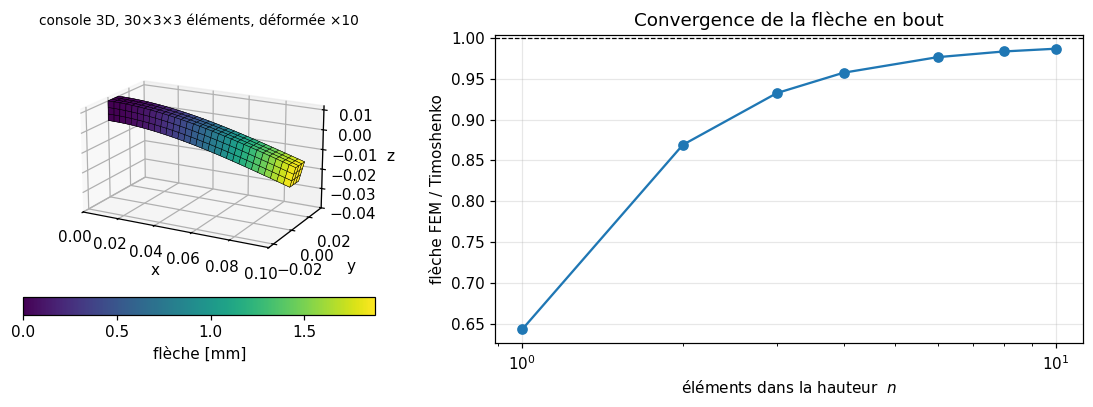

In [15]:
# --- figure : convergence et maillage déformé (n = 3, déplacements amplifiés)
def faces_de_bord(P):
    # quadrilatères des six faces extérieures d'un tableau (nx+1, ny+1, nz+1, c)
    q = []
    for axe in range(3):
        for cote in (0, -1):
            S = np.take(P, cote, axis=axe)
            q += [[S[i, j], S[i + 1, j], S[i + 1, j + 1], S[i, j + 1]] for i in range(S.shape[0] - 1) for j in range(S.shape[1] - 1)]
    return np.array(q)

r = res[2]                                         # n = 3 : 30 x 3 x 3 éléments
g, noeuds, u = r["g"], r["noeuds"], r["u"]
coord = np.stack(np.meshgrid(*[np.arange(n + 1) * hk for n, hk in zip(g.shape, g.h)], indexing="ij"), axis=-1)
U = u.reshape(g.n_nodes, 3)[noeuds]                # (nx+1, ny+1, nz+1, 3) : déplacement de chaque nœud
amplif = 10.0
quads = faces_de_bord(coord + amplif * U)
couleur = faces_de_bord(-U[..., 2:3])[..., 0].mean(axis=1) * 1e3     # flèche (mm) moyenne de chaque face

fig = plt.figure(figsize=(11, 3.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
pc = Poly3DCollection(quads, edgecolor="k", linewidths=0.3)
pc.set_array(couleur); pc.set_cmap("viridis"); ax.add_collection3d(pc)
ax.set_xlim(0, L); ax.set_ylim(-0.025, 0.035); ax.set_zlim(-0.04, 0.012)
ax.set_box_aspect((L, 0.06, 0.052)); ax.view_init(elev=18, azim=-62)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title(f"console 3D, 30×3×3 éléments, déformée ×{amplif:.0f}", fontsize=9)
fig.colorbar(pc, ax=ax, shrink=0.6, label="flèche [mm]", location="bottom", pad=0.02)
ax2 = fig.add_subplot(1, 2, 2)
ax2.semilogx(ns, [r["fleche"] / d_timo for r in res], "o-")
ax2.axhline(1, color="k", lw=0.8, ls="--")
ax2.set_xlabel("éléments dans la hauteur  $n$"); ax2.set_ylabel("flèche FEM / Timoshenko")
ax2.set_title("Convergence de la flèche en bout"); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Lecture.**

- **Verrouillage** : à $n=1$ (un seul élément dans la section) la flèche est sous-estimée de plus d'un tiers, comme en 2D (notebook 3) : l'hexaèdre Q1 est trop raide en flexion quand il est peu raffiné. Avec 4 éléments dans l'épaisseur l'erreur est encore de 4 %, avec 8 de 1,6 % : c'est l'un des arguments de la règle du projet « rayon de filtre $R\ge3h$ ».
- **Convergence** : le rapport monte de $0{,}64$ à $0{,}987$ ; il ne dépasse jamais 1 (l'élément reste trop raide) et ses accroissements diminuent ($0{,}977\to0{,}984\to0{,}987$ pour $n=6,8,10$). Un écart résiduel d'environ 1 % avec la théorie est attendu : Timoshenko suppose des sections qui se déforment librement, alors que l'**encastrement 3D** bloque aussi la contraction de Poisson de la section. Le test ci-dessous va dans ce sens : sans effet de Poisson ($\nu=0$), l'écart est divisé par deux.

In [16]:
for nu_ in (0.3, 0.0):
    m_ = Orthotropic.isotropic(E, nu_)
    f_, c_ = timoshenko(E, nu_, L, W, H, F)
    r_ = console_3d(m_, L, W, H, 8, F)
    print(f"nu = {nu_:.1f} : FEM / Timoshenko (n = 8) = {r_['fleche'] / (f_ + c_):.4f}")

nu = 0.3 : FEM / Timoshenko (n = 8) = 0.9836


nu = 0.0 : FEM / Timoshenko (n = 8) = 0.9922


À $n=8$, l'écart à la théorie passe de $1{,}6\,\%$ ($\nu=0{,}3$) à $0{,}8\,\%$ ($\nu=0$) : l'encastrement 3D explique une bonne part de l'écart (le reste est l'erreur de discrétisation, qui diminue avec $n$). On retient que l'élément et l'assemblage 3D sont **corrects** : ils convergent vers la solution de la théorie des poutres, à 1 % près, avec le même défaut de verrouillage que le 2D.

## 8. Le coût de la 3D

Tout fonctionne : pourquoi ne pas résoudre directement des problèmes 3D comme des problèmes 2D ? Parce que **tout grossit** quand on passe en 3D, et pas seulement de manière proportionnelle. On mesure, sur un problème de même nature (un carré $1\times1$ en 2D, un cube $1\times1\times1$ en 3D, encastrés sur la face $x=0$, maillés en $n^d$ éléments), quatre quantités :

1. le nombre d'inconnues $N$ ;
2. le nombre de coefficients non nuls par ligne de $\mathbf K$ (chaque nœud « voit » ses voisins : 9 nœuds en 2D, 27 en 3D) ;
3. le **remplissage** d'une factorisation directe LU : le nombre de coefficients non nuls de $\mathbf L+\mathbf U$ divisé par celui de $\mathbf K$ (la factorisation « remplit » des zéros) ;
4. le **conditionnement** $\kappa(\mathbf K)=\lambda_{\max}/\lambda_{\min}$, qui gouverne la vitesse des méthodes itératives (leçon 5).

In [17]:
def etude(d, n):
    g = Grid((n,) * d, (1.0 / n,) * d)
    K = assembler(g, el.elasticity_ke0(d, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(d, "stress")), d)
    noeuds = np.arange(g.n_nodes).reshape((n + 1,) * d)
    bloques = (d * noeuds[0].ravel()[:, None] + np.arange(d)).ravel()
    libres = np.setdiff1d(np.arange(K.shape[0]), bloques)
    Kl = K[libres][:, libres].tocsc()
    t0 = time.perf_counter(); lu = spla.splu(Kl); lu.solve(np.ones(Kl.shape[0])); temps = time.perf_counter() - t0
    lmax = spla.eigsh(Kl, k=1, which="LA", return_eigenvectors=False)[0]
    lmin = spla.eigsh(Kl, k=1, sigma=0, which="LM", return_eigenvectors=False)[0]
    return dict(n=n, N=Kl.shape[0], nnz_ligne=Kl.nnz / Kl.shape[0], remplissage=(lu.L.nnz + lu.U.nnz) / Kl.nnz,
                temps=temps, cond=lmax / lmin)

etudes = {2: [etude(2, n) for n in (4, 8, 16, 32, 64, 128)],
          3: [etude(3, n) for n in (2, 4, 6, 8, 12, 16, 20)]}
for d in (2, 3):
    print(f"\n{d}D : {'n':>4s} {'inconnues':>10s} {'nnz/ligne':>10s} {'remplissage LU':>15s} {'temps LU [s]':>13s} {'cond(K)':>10s}")
    for e in etudes[d]:
        print(f"      {e['n']:4d} {e['N']:10d} {e['nnz_ligne']:10.1f} {e['remplissage']:15.1f} {e['temps']:13.3f} {e['cond']:10.1e}")


2D :    n  inconnues  nnz/ligne  remplissage LU  temps LU [s]    cond(K)
         4         40       13.0             1.7         0.000    2.4e+02
         8        144       15.3             2.3         0.000    8.4e+02
        16        544       16.6             3.6         0.001    3.0e+03
        32       2112       17.3             5.6         0.006    1.1e+04
        64       8320       17.6            11.1         0.047    4.3e+04
       128      33024       17.8            14.7         0.312    1.7e+05

3D :    n  inconnues  nnz/ligne  remplissage LU  temps LU [s]    cond(K)
         2         54       32.7             1.5         0.000    9.3e+01
         4        300       50.7             3.9         0.001    3.3e+02
         6        882       58.9             4.3         0.007    6.7e+02
         8       1944       63.7             7.2         0.041    1.1e+03
        12       6084       68.9            11.6         0.328    2.2e+03
        16      13872       71.7      

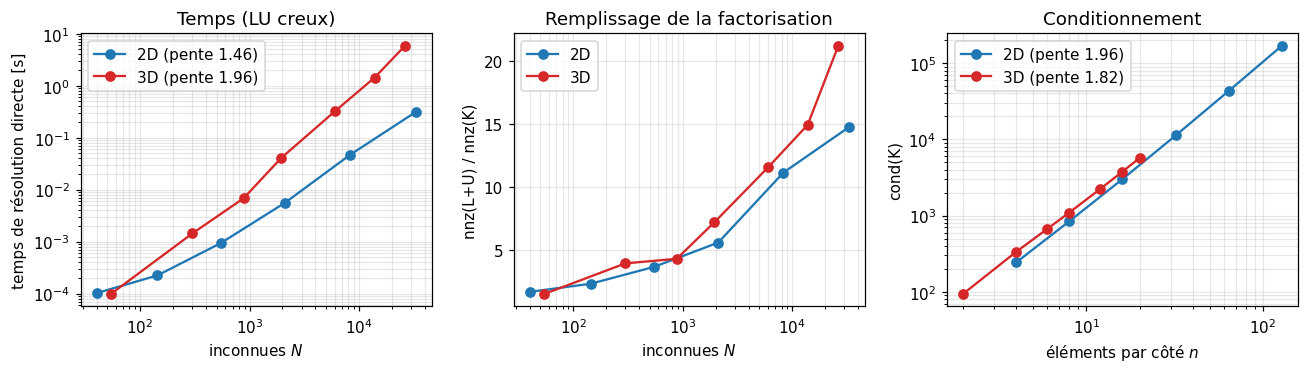

à N voisin : 2D (N = 33024) : 0.31 s, L+U = 8.7 M coefficients, cond = 1.7e+05
             3D (N = 26460) : 5.92 s, L+U = 41.2 M coefficients, cond = 5.7e+03
extrapolation du temps 3D à N = 1e6 avec la pente mesurée : 2.0 h


In [18]:
def exposant(es, cle, x="N", k=3):
    # pente log-log sur les k derniers points
    a, b = np.log([e[x] for e in es[-k:]]), np.log([e[cle] for e in es[-k:]])
    return np.polyfit(a, b, 1)[0]

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for d, c in ((2, "C0"), (3, "C3")):
    es = etudes[d]
    N = [e["N"] for e in es]
    axs[0].loglog(N, [e["temps"] for e in es], "o-", color=c, label=f"{d}D (pente {exposant(es, 'temps'):.2f})")
    axs[1].semilogx(N, [e["remplissage"] for e in es], "o-", color=c, label=f"{d}D")
    axs[2].loglog([e["n"] for e in es], [e["cond"] for e in es], "o-", color=c,
                  label=f"{d}D (pente {exposant(es, 'cond', 'n'):.2f})")
axs[0].set_xlabel("inconnues $N$"); axs[0].set_ylabel("temps de résolution directe [s]"); axs[0].set_title("Temps (LU creux)")
axs[1].set_xlabel("inconnues $N$"); axs[1].set_ylabel("nnz(L+U) / nnz(K)"); axs[1].set_title("Remplissage de la factorisation")
axs[2].set_xlabel("éléments par côté $n$"); axs[2].set_ylabel("cond(K)"); axs[2].set_title("Conditionnement")
for a in axs: a.grid(alpha=0.3, which="both"); a.legend()
plt.tight_layout(); plt.show()

e2, e3 = etudes[2][-1], etudes[3][-1]
nnz_lu = lambda e: e["remplissage"] * e["nnz_ligne"] * e["N"]          # coefficients de L + U
print(f"à N voisin : 2D (N = {e2['N']}) : {e2['temps']:.2f} s, L+U = {nnz_lu(e2) / 1e6:.1f} M coefficients, cond = {e2['cond']:.1e}")
print(f"             3D (N = {e3['N']}) : {e3['temps']:.2f} s, L+U = {nnz_lu(e3) / 1e6:.1f} M coefficients, cond = {e3['cond']:.1e}")
print(f"extrapolation du temps 3D à N = 1e6 avec la pente mesurée : {e3['temps'] * (1e6 / e3['N']) ** exposant(etudes[3], 'temps') / 3600:.1f} h")

**Lecture.**

- **Coefficients par ligne** : environ 18 en 2D ($9\text{ nœuds}\times2$ ddl) et environ 73 déjà à $n=20$ en 3D, vers 81 ($27\times3$) à la limite. Une ligne de $\mathbf K$ en 3D contient donc environ **4 fois plus** de coefficients qu'en 2D.
- **Remplissage et temps** : le remplissage d'une factorisation directe croît avec $N$ dans les deux cas, plus vite en 3D. Le temps de résolution directe croît environ comme $N^{1{,}5}$ en 2D mais comme $N^{2}$ en 3D : à nombre d'inconnues comparable (une trentaine de milliers), la 3D est une vingtaine de fois plus lente et ses facteurs $\mathbf L,\mathbf U$ occupent environ 5 fois plus de mémoire (voir l'affichage ci-dessus). Extrapolé avec la pente mesurée (simple ordre de grandeur), un problème 3D de $10^6$ inconnues, la taille d'un bras de drone raisonnablement fin (notebook 1), demanderait de l'ordre de deux heures de factorisation : un solveur direct n'est plus envisageable.
- **Conditionnement** : il croît comme $n^{1{,}8\text{ à }2}\approx h^{-2}$ **dans les deux cas** ; à $n$ égal les deux courbes sont proches. À $N$ égal la 3D est même mieux conditionnée ($5{,}7\cdot10^3$ pour 26 000 inconnues, contre $1{,}7\cdot10^5$ pour 33 000 inconnues en 2D) car un cube de même $N$ a un $n$ bien plus petit. Ce qui explose en 3D, c'est donc le *coût*, pas le conditionnement. Mais un $\kappa\propto h^{-2}$ ralentit les méthodes itératives, ce qui est l'objet de la leçon 5.

Ces trois constats justifient la suite du cours : la **leçon 5** compare solveur direct et itératif (gradient conjugué, qui n'a besoin que de produits matrice-vecteur), et la **leçon 6** supprime le stockage de $\mathbf K$ lui-même, en n'utilisant que la petite matrice $24\times24$ de ce notebook.

## À retenir

| Idée | Dans le projet |
|---|---|
| Un seul code, valable en 2D et 3D, grâce au code binaire des coins : $N_a=\prod_k(1+s_{a,k}\xi_k)/2$ | `fem/elements.py` (`local_node_signs`, `shape_values`, `shape_grads`, `strain_displacement`, `elasticity_ke0`) |
| $\mathbf B$ : $6\times24$ ; $\mathbf K_e^0=\sum_g w_g\det\mathbf J\,\mathbf B_g^\top\mathbf C_0\mathbf B_g$, Gauss $2\times2\times2$ **exact** sur grille régulière | matrice élémentaire $24\times24$, **une seule** pour toute la grille |
| 6 modes rigides (3 translations, 3 rotations), symétrie, patch test, 3D $\supset$ 2D (déformations planes), oracle à boucles | `tests/unit/test_element.py`, `tests/reference/assembly_numpy.py` |
| Loi 3D $\mathbf C_0=\mathbf S^{-1}$ ($6\times6$), `Orthotropic.stiffness(3)` | `materials.py` |
| Connectivité vectorisée, ddl $=d\,n+c$, nœud en ordre C | `grid.py::Connectivity` |
| Console 3D : convergence vers Timoshenko (0,99 à $n=10$), verrouillage à $n=1$ | validation de la brique mécanique 3D |
| Coûts 3D : ~4× plus de coefficients par ligne, temps de LU en $\sim N^2$ (2D : $N^{1{,}5}$), $\kappa\propto h^{-2}$ | motivation du solveur itératif (leçon 5) et de l'opérateur sans matrice (leçon 6) |

**Pour expérimenter.** (i) Dans le §7, remplacez `mat_iso` par `Orthotropic.transversely_isotropic(2.4e9, 1.8e9, 0.35, 0.35, 0.7e9)` : la flèche est multipliée par environ $0{,}84$ (mesuré : $0{,}836$ à $n=6$ ; $E/E_p=0{,}83$). Pourquoi la flexion le long de $x$ ne « voit »-elle presque que $E_p$ ? (ii) Prenez une section de largeur double ($W=20$ mm) : la flèche est divisée par 2 (rapport mesuré : $0{,}497$), car $I$ double. (iii) Observez la flèche d'une pièce non symétrique : décalez la charge en $y$ (donnez des poids non nuls seulement aux nœuds $y=0$). Quel nouveau mouvement apparaît, que le 2D ne pouvait pas représenter ?

*Suite : leçon 5 (résoudre $\mathbf K\mathbf u=\mathbf f$ : direct ou itératif), puis leçon 6 (opérateur sans matrice). Voir le [plan des leçons](README.md).*